# Stronger XGBoost with longer patience

`regularization_curves.ipynb` showed that a patience of 30 trees often stopped Stronger XGBoost too early, so `regularization.ipynb` wasn't a full test of it. This reruns that candidate with one change: **patience goes from 30 to 75 trees**. The learning rate is 2.5 times lower than the control's (0.02 against 0.05), so patience is 2.5 times longer.

**The progress criteria stay the same:** correlation clearly above zero, an R² interval reaching or crossing zero, and direction closer to or above always-up. Wider predictions, or better MSE from flatter predictions, aren't enough. A winner needs a 5-seed rerun before it's trusted.

This uses the same 3 seeds as the other candidates, with common dates, standardization and the 1-day horizon. The test split stays locked.

In [1]:
from pathlib import Path
import sys

import pandas as pd

# notebook is in training/benchmarking/notebooks, parents[1] points to training/
sys.path.insert(0, str(Path.cwd().parents[1]))

from benchmarking.diagnostics import early_stopping_pick
from benchmarking.regularization import (
    CONTROL,
    STRONGER_XGBOOST_LONG_PATIENCE,
    compare_to_control,
    for_base_model,
    run_regularization_split,
    run_regularization_walk_forward,
    with_control,
)
from benchmarking.result_plots import TRACK_TITLES, plot_split_results, plot_track_comparisons, plot_walk_forward_intervals
from benchmarking.walk_forward import TRACK_COMPARISONS, compare_tracks, correlation_intervals, score_walk_forward, walk_forward_intervals

RESULTS_DIR = Path.cwd().parent / "results"
PREFIX = "regularization_patience_75"
STRONGER = "XGBoost | Stronger"
LONG_PATIENCE = STRONGER_XGBOOST_LONG_PATIENCE.name

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 100, "display.float_format", "{:.4f}".format)

## Training

108 fits: 96 on walk-forward and 12 on 80/10/10. Saved work is skipped.

In [2]:
run_regularization_walk_forward(RESULTS_DIR / f"{PREFIX}_walk_forward_predictions.csv", (STRONGER_XGBOOST_LONG_PATIENCE,))
run_regularization_split(
    RESULTS_DIR / f"{PREFIX}_split_seed_metrics.csv",
    RESULTS_DIR / f"{PREFIX}_split_predictions.csv",
    (STRONGER_XGBOOST_LONG_PATIENCE,),
)

no_news_no_feature_engineering: round 1 of 8 done


no_news_no_feature_engineering: round 2 of 8 done

no_news_no_feature_engineering: round 3 of 8 done

no_news_no_feature_engineering: round 4 of 8 done


no_news_no_feature_engineering: round 5 of 8 done


no_news_no_feature_engineering: round 6 of 8 done


... (26 outputs left out)

80/10/10: no_news_no_feature_engineering done


80/10/10: no_news_with_feature_engineering done


80/10/10: news_with_feature_engineering done


80/10/10: news_with_feature_engineering_and_tech done


## Load saved results

The new runs, patience 30 from `regularization.ipynb`, and the control, on the same seeds. Only XGBoost is kept.

In [3]:
def load(new_name, old_name, unified_name):
    new = pd.read_csv(RESULTS_DIR / f"{PREFIX}_{new_name}.csv")
    old = pd.read_csv(RESULTS_DIR / f"regularization_{old_name}.csv")
    combined = with_control(pd.concat([new, old[old["model"] == STRONGER]], ignore_index=True), pd.read_csv(RESULTS_DIR / f"unified_{unified_name}.csv"))
    return combined[combined["model"].str.startswith("XGBoost")].reset_index(drop=True)


walk_forward = load("walk_forward_predictions", "walk_forward_predictions", "walk_forward_predictions")
split_metrics = load("split_seed_metrics", "split_seed_metrics", "split_seed_metrics")


def scale_mse(table, columns):
    """Show tiny MSE values multiplied by 10,000."""
    return table.assign(**{column: table[column] * 1e4 for column in columns})

## Check against the saved curves

Replaying patience 75 on seed 42's curves should give the same trees as this run, since early stopping doesn't change how trees are built.

In [4]:
FIT_KEYS = ["track", "model", "seed", "round"]
fits = walk_forward.drop_duplicates(FIT_KEYS)
curves = pd.read_csv(RESULTS_DIR / "regularization_curves.csv")
curves = curves[curves["model"] == STRONGER]
replayed = (
    curves.sort_values("step").groupby(["track", "seed", "round"])["stopping_loss"]
    .apply(lambda losses: early_stopping_pick(losses.to_numpy(), 75))
    .rename("replayed").reset_index()
)
matched = fits[fits["model"] == LONG_PATIENCE].merge(replayed, on=["track", "seed", "round"])
print(f"{(matched['best_step'] == matched['replayed']).sum()} of {len(matched)} picks match")

12 of 12 picks match


## Walk-forward

### Walk-forward: results with confidence intervals

781 scored days. `oos_r2` is R² against the train-mean baseline. MSE values are shown multiplied by 10,000.

In [5]:
intervals = walk_forward_intervals(walk_forward)
intervals.to_csv(RESULTS_DIR / f"{PREFIX}_walk_forward_intervals.csv", index=False)
scale_mse(intervals, ["mse", "baseline_mse"]).drop(columns=["horizon", "days"])

,track,model,mse,baseline_mse,oos_r2,oos_r2_lower,oos_r2_upper,directional_accuracy,always_up_accuracy,direction_edge,direction_edge_lower,direction_edge_upper
0,no_news_no_feature_engineering,XGBoost | Control,11.8449,11.5200,-0.0282,-0.0497,-0.0104,0.5241,0.5493,-2.5181,-5.1643,-0.2977
1,no_news_with_feature_engineering,XGBoost | Control,11.8686,11.5200,-0.0303,-0.0529,-0.0095,0.5271,0.5493,-2.2194,-5.1216,0.5975
2,news_with_feature_engineering,XGBoost | Control,11.8409,11.5200,-0.0279,-0.0430,-0.0154,0.4994,0.5493,-4.9936,-7.4264,-2.5608
3,news_with_feature_engineering_and_tech,XGBoost | Control,11.8365,11.5200,-0.0275,-0.0480,-0.0085,0.5216,0.5493,-2.7742,-5.7618,0.2561
4,no_news_no_feature_engineering,"XGBoost | Stronger, patience 75",11.6370,11.5200,-0.0102,-0.0205,-0.0010,0.5318,0.5493,-1.7499,-4.0120,0.0427
5,no_news_with_feature_engineering,"XGBoost | Stronger, patience 75",11.6917,11.5200,-0.0149,-0.0283,-0.0040,0.5237,0.5493,-2.5608,-4.9082,-0.3841
6,news_with_feature_engineering,"XGBoost | Stronger, patience 75",11.6066,11.5200,-0.0075,-0.0154,-0.0004,0.5288,0.5493,-2.0487,-4.3545,0.0011
7,news_with_feature_engineering_and_tech,"XGBoost | Stronger, patience 75",11.6294,11.5200,-0.0095,-0.0179,-0.0021,0.5301,0.5493,-1.9206,-4.1400,-0.1280
8,no_news_no_feature_engineering,XGBoost | Stronger,11.5269,11.5200,-0.0006,-0.0044,0.0032,0.5416,0.5493,-0.7682,-1.8779,0.1707
9,no_news_with_feature_engineering,XGBoost | Stronger,11.6091,11.5200,-0.0077,-0.0143,-0.0018,0.5305,0.5493,-1.8779,-3.2864,-0.5548


### Walk-forward: chart

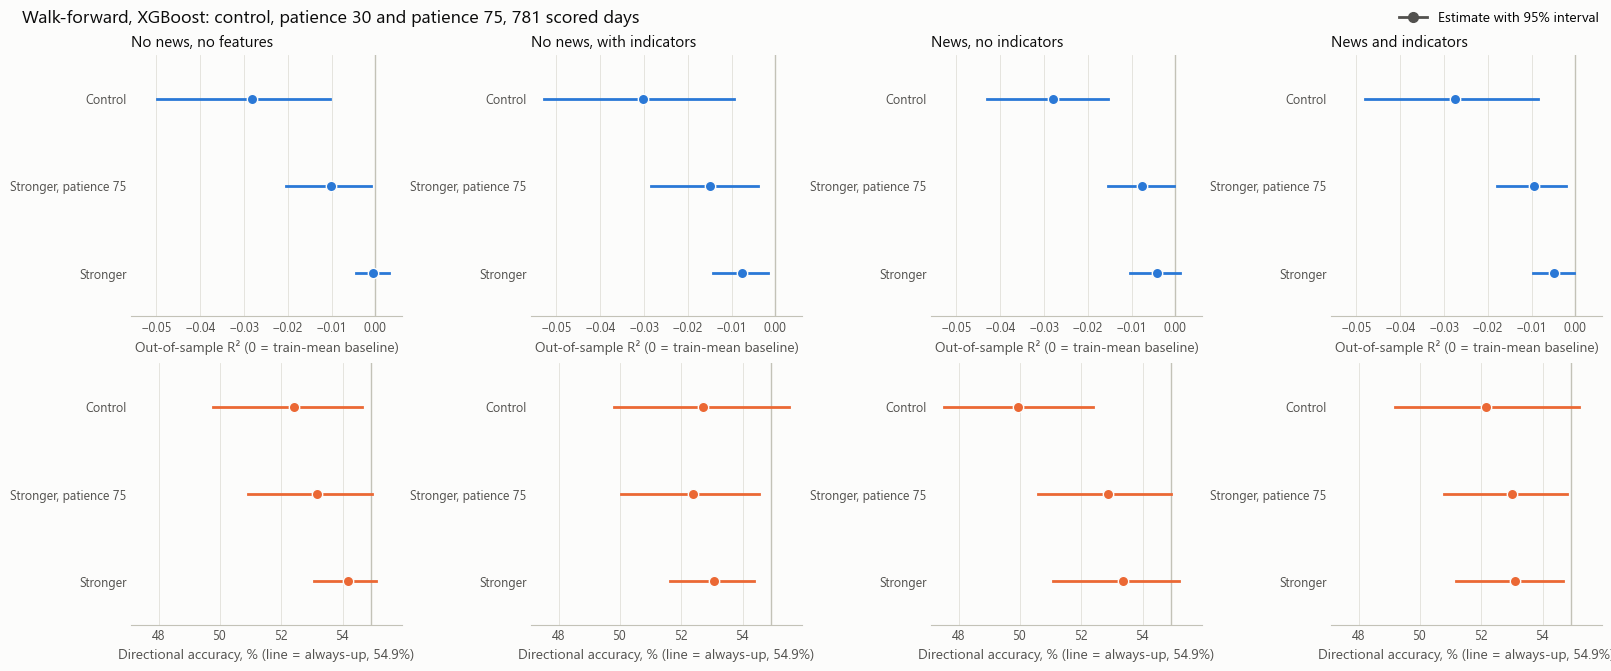

In [6]:
plot_walk_forward_intervals(
    for_base_model(intervals, "XGBoost"),
    title="Walk-forward, XGBoost: control, patience 30 and patience 75, 781 scored days",
)

### Walk-forward: are predictions still flat, and is signal appearing?

`correlation` is with actual returns, and `spread_ratio` is prediction spread divided by actual spread. `best_step` is the tree count used, and `share_at_limit` is how often a fit reached 500 trees.

In [7]:
stopping = fits.assign(at_limit=fits["steps_run"] >= 500).groupby(["track", "model"], sort=False).agg(
    best_step=("best_step", "mean"), median_step=("best_step", "median"), share_at_limit=("at_limit", "mean")
)
scores = score_walk_forward(walk_forward).groupby(["track", "model"], sort=False)[["correlation", "spread_ratio", "oos_r2"]].mean()
scores["share_predicted_up"] = walk_forward.assign(up=walk_forward["predicted"] > 0).groupby(["track", "model"], sort=False)["up"].mean()
scores.join(stopping)

,,correlation,spread_ratio,oos_r2,share_predicted_up,best_step,median_step,share_at_limit
track,model,,,,,,,
no_news_no_feature_engineering,XGBoost | Control,-0.0534,0.1271,-0.0282,0.8203,31.6667,13.5000,0.0000
no_news_with_feature_engineering,XGBoost | Control,-0.0384,0.1412,-0.0303,0.8071,34.2500,12.5000,0.0000
news_with_feature_engineering,XGBoost | Control,-0.0542,0.1220,-0.0279,0.8071,26.5417,15.0000,0.0000
news_with_feature_engineering_and_tech,XGBoost | Control,-0.0428,0.1331,-0.0275,0.7840,26.1667,12.0000,0.0000
no_news_no_feature_engineering,"XGBoost | Stronger, patience 75",-0.0272,0.0855,-0.0102,0.9065,104.0833,5.0000,0.1667
no_news_with_feature_engineering,"XGBoost | Stronger, patience 75",-0.0391,0.0953,-0.0149,0.8694,111.4583,14.5000,0.1250
news_with_feature_engineering,"XGBoost | Stronger, patience 75",-0.0309,0.0655,-0.0075,0.8600,50.7083,21.0000,0.0000
news_with_feature_engineering_and_tech,"XGBoost | Stronger, patience 75",-0.0350,0.0759,-0.0095,0.8613,86.3750,26.0000,0.0833
no_news_no_feature_engineering,XGBoost | Stronger,-0.0187,0.0346,-0.0006,0.9607,21.1250,3.0000,0.0000


### Walk-forward: correlation with confidence intervals

Predictions are averaged across seeds per day first, so these values differ from the seed averages above.

In [8]:
correlations = correlation_intervals(walk_forward)
correlations.to_csv(RESULTS_DIR / f"{PREFIX}_correlation_intervals.csv", index=False)
correlations.drop(columns="horizon")

,track,model,correlation,correlation_lower,correlation_upper
0,no_news_no_feature_engineering,XGBoost | Control,-0.0610,-0.1315,0.0090
1,no_news_with_feature_engineering,XGBoost | Control,-0.0476,-0.1161,0.0316
2,news_with_feature_engineering,XGBoost | Control,-0.0679,-0.1235,-0.0153
3,news_with_feature_engineering_and_tech,XGBoost | Control,-0.0513,-0.1188,0.0253
4,no_news_no_feature_engineering,"XGBoost | Stronger, patience 75",-0.0296,-0.0762,0.0236
5,no_news_with_feature_engineering,"XGBoost | Stronger, patience 75",-0.0422,-0.0972,0.0169
6,news_with_feature_engineering,"XGBoost | Stronger, patience 75",-0.0348,-0.1019,0.0312
7,news_with_feature_engineering_and_tech,"XGBoost | Stronger, patience 75",-0.0341,-0.0886,0.0246
8,no_news_no_feature_engineering,XGBoost | Stronger,-0.0185,-0.0801,0.0474
9,no_news_with_feature_engineering,XGBoost | Stronger,-0.0670,-0.1217,-0.0110


### Walk-forward: results by round

Out-of-sample R² for each round, averaged across seeds and input sets.

In [9]:
by_round = score_walk_forward(walk_forward, by_round=True)
by_round.pivot_table(index="round", columns="model", values="oos_r2")

model,XGBoost | Control,XGBoost | Stronger,"XGBoost | Stronger, patience 75"
round,,,
1,-0.0278,-0.0083,-0.0083
2,-0.0093,-0.0007,-0.0055
3,-0.0022,-0.0025,-0.0025
4,-0.0528,0.0002,-0.0270
5,-0.0455,-0.0033,-0.0069
6,-0.0196,-0.0050,-0.0050
7,0.0041,0.0031,0.0031
8,-0.1100,-0.0186,-0.0504


## Direct comparisons

The same days, compared day by day within each input set. Positive differences favor the first model named.

### Direct comparisons: patience 75 against the control and patience 30

MSE values are shown multiplied by 10,000.

In [10]:
against_control = compare_to_control(walk_forward, "XGBoost")
against_control = against_control[against_control["comparison"].str.contains("patience 75")]
without_control = walk_forward[~walk_forward["model"].str.endswith(CONTROL)]
against_patience_30 = compare_to_control(without_control, "XGBoost", control="Stronger")
comparisons = pd.concat([against_control, against_patience_30], ignore_index=True)
comparisons.to_csv(RESULTS_DIR / f"{PREFIX}_comparisons.csv", index=False)
scale_mse(comparisons, ["mse_first", "mse_second", "mse_improvement", "mse_improvement_lower", "mse_improvement_upper"]).drop(columns=["first_track", "second_track", "horizon", "days"])

,comparison,track,mse_first,mse_second,mse_improvement,mse_improvement_lower,mse_improvement_upper,accuracy_first,accuracy_second,direction_gain,direction_gain_lower,direction_gain_upper
0,"Stronger, patience 75 vs control",no_news_no_feature_engineering,11.6370,11.8449,0.2079,0.0691,0.3738,0.5318,0.5241,0.7682,-0.8536,2.4755
1,"Stronger, patience 75 vs control",no_news_with_feature_engineering,11.6917,11.8686,0.1769,0.0022,0.3775,0.5237,0.5271,-0.3414,-2.2621,1.7926
2,"Stronger, patience 75 vs control",news_with_feature_engineering,11.6066,11.8409,0.2343,0.1227,0.3661,0.5288,0.4994,2.9449,1.1524,4.7375
3,"Stronger, patience 75 vs control",news_with_feature_engineering_and_tech,11.6294,11.8365,0.2070,0.0290,0.4115,0.5301,0.5216,0.8536,-1.4938,3.2437
4,"Stronger, patience 75 vs Stronger",no_news_no_feature_engineering,11.6370,11.5269,-0.1101,-0.2117,-0.0278,0.5318,0.5416,-0.9816,-2.5608,0.2561
5,"Stronger, patience 75 vs Stronger",no_news_with_feature_engineering,11.6917,11.6091,-0.0826,-0.1776,-0.0026,0.5237,0.5305,-0.6829,-2.3047,0.9390
6,"Stronger, patience 75 vs Stronger",news_with_feature_engineering,11.6066,11.5692,-0.0374,-0.0869,-0.0018,0.5288,0.5335,-0.4695,-1.3231,0.2134
7,"Stronger, patience 75 vs Stronger",news_with_feature_engineering_and_tech,11.6294,11.5760,-0.0535,-0.1044,-0.0109,0.5301,0.5309,-0.0854,-0.8120,0.6413


### Direct comparisons: chart

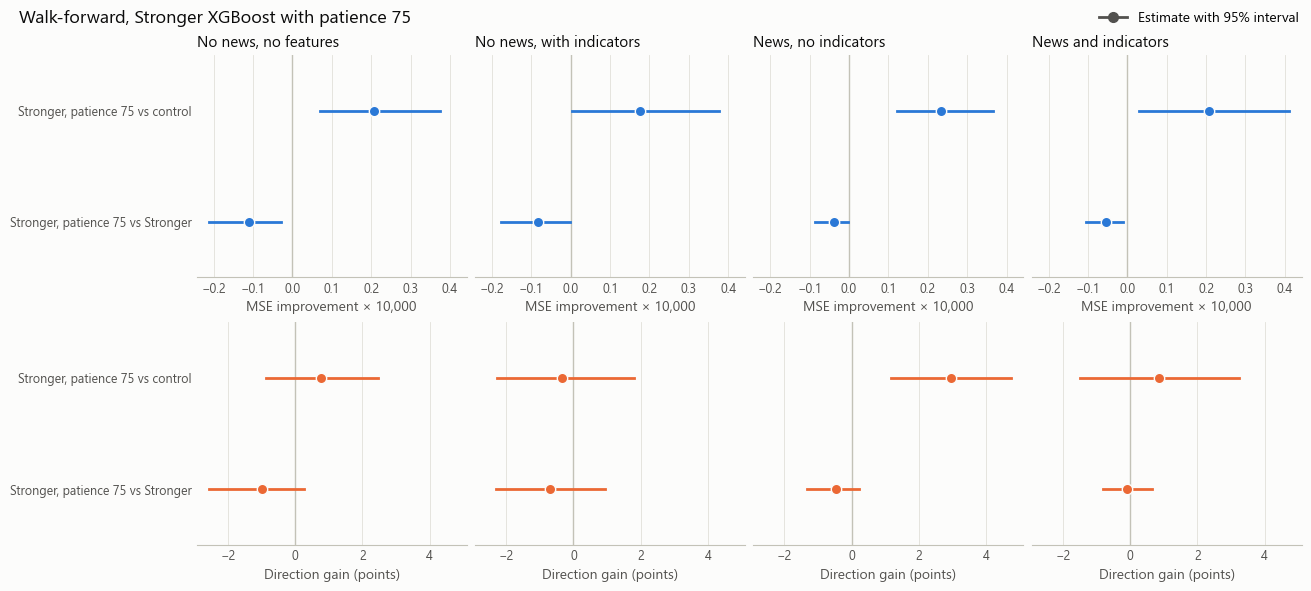

In [11]:
plot_track_comparisons(
    comparisons.assign(model=comparisons["track"].map(TRACK_TITLES)),
    title="Walk-forward, Stronger XGBoost with patience 75",
)

### News against no news

News, no indicators against no news, no features, where news is the only difference. Positive differences favor news. MSE values are shown multiplied by 10,000.

In [12]:
news = compare_tracks(walk_forward, TRACK_COMPARISONS[:1])
scale_mse(news, ["mse_first", "mse_second", "mse_improvement", "mse_improvement_lower", "mse_improvement_upper"]).drop(columns=["first_track", "second_track", "horizon", "days"] + ["comparison"])

,model,mse_first,mse_second,mse_improvement,mse_improvement_lower,mse_improvement_upper,accuracy_first,accuracy_second,direction_gain,direction_gain_lower,direction_gain_upper
0,XGBoost | Control,11.8409,11.8449,0.0040,-0.1349,0.1700,0.4994,0.5241,-2.4755,-4.1827,-0.7682
1,"XGBoost | Stronger, patience 75",11.6066,11.6370,0.0304,-0.0883,0.1451,0.5288,0.5318,-0.2988,-2.5608,2.0060
2,XGBoost | Stronger,11.5692,11.5269,-0.0423,-0.1156,0.0209,0.5335,0.5416,-0.8109,-2.5192,0.8109


## 80/10/10 split

### 80/10/10: chart

The 123 validation days, which aren't used for early stopping.

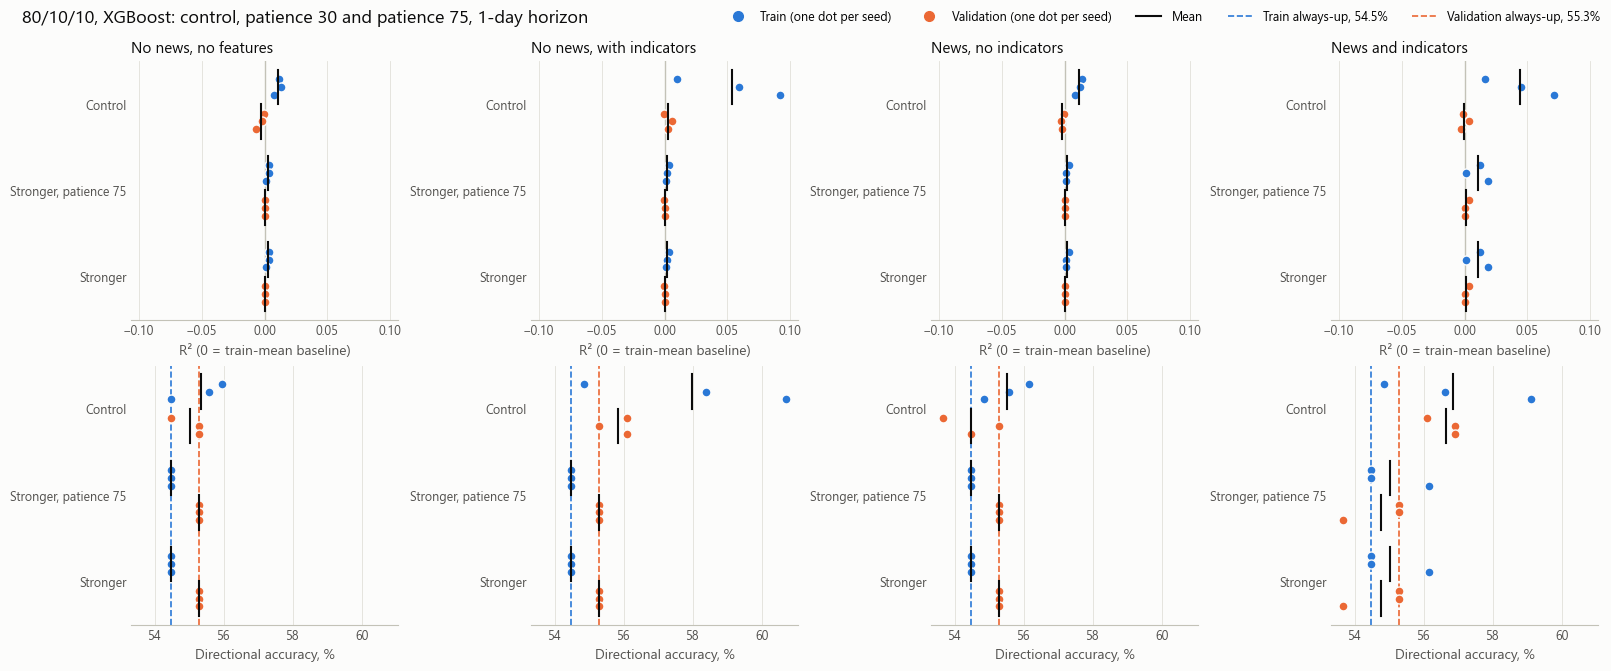

In [13]:
plot_split_results(
    for_base_model(split_metrics, "XGBoost"),
    r2_limits=(-0.1, 0.1),
    title="80/10/10, XGBoost: control, patience 30 and patience 75, 1-day horizon",
)

### 80/10/10: summary table

In [14]:
table = split_metrics.assign(oos_r2=1 - split_metrics["mse"] / split_metrics["baseline_mse"])
table.pivot_table(index=["track", "model"], columns="split", values=["oos_r2", "directional_accuracy", "correlation"], sort=False)

oos_r2            directional_accuracy            correlation           
split                                                                   train validation                train validation       train validation
track                                  model                                                                                                   
no_news_no_feature_engineering         XGBoost | Control               0.0109    -0.0028               0.5533     0.5501      0.3317    -0.0545
                                       XGBoost | Stronger, patience 75 0.0027     0.0002               0.5446     0.5528      0.1938     0.0239
                                       XGBoost | Stronger              0.0027     0.0002               0.5446     0.5528      0.1938     0.0239
no_news_with_feature_engineering       XGBoost | Control               0.0536     0.0029               0.5796     0.5583      0.4825     0.0498
                                       XGBoost | Stronger, patience 75 0.0020     0.0002               0.5446     0.5528      0.1555     0.0355
                                       XGBoost | Stronger              0.0020     0.0002               0.5446     0.5528      0.1555     0.0355
news_with_feature_engineering          XGBoost | Control               0.0117    -0.0016               0.5551     0.5447      0.3448    -0.0252
                                       XGBoost | Stronger, patience 75 0.0019     0.0005               0.5446     0.5528      0.1620     0.0573
                                       XGBoost | Stronger              0.0019     0.0005               0.5446     0.5528      0.1620     0.0573
news_with_feature_engineering_and_tech XGBoost | Control               0.0441    -0.0003               0.5685     0.5664      0.5001     0.0121
                                       XGBoost | Stronger, patience 75 0.0106     0.0015               0.5502     0.5474      0.2994     0.0666
                                       XGBoost | Stronger              0.0106     0.0015               0.5502     0.5474      0.2994     0.0666

## Conclusions

**Longer patience made Stronger XGBoost worse, so short patience wasn't hiding signal.** It didn't meet the progress criteria, and it doesn't need a 5-seed rerun.

- **R²:** worse than patience 30 on all 4 input sets, with intervals that exclude zero. It ranges from -0.0075 to -0.0149, and no R² interval reaches zero now.
- **Correlation:** still negative, from -0.030 to -0.042, and every interval includes zero.
- **Direction:** 52.4-53.2%, still below always-up at 54.9%.
- **Stopping-slice gains didn't carry over:** rounds 4 and 8 trained for the most extra trees, and looked best on the stopping slice, but they got worse on scored days. Round 4's R² goes from 0.0002 to -0.027, and round 8's from -0.019 to -0.050.
- **Against the control:** it still beats the control on MSE on all 4 input sets, but with flatter predictions (spread 0.07-0.10 against 0.12-0.14) and no correlation, which the criteria rule out.
- **News against no news:** both intervals include zero.
- **80/10/10:** this can't separate the two settings. Both pick the same trees in all 12 fits, between 1 and 15, so the results are identical.